# Data Transformation

## 1. What Is Data Transformation?

Data transformation is the process of changing the format, scale, or distribution of data to make it more suitable for analysis and machine learning.

Sometimes, raw data does not follow a distribution that works well with certain machine learning algorithms. Transformation techniques can help reduce skewness, make patterns easier to identify, and improve model performance.

**Example:**

Suppose a company's employee salary data is:

* ₹20,000
* ₹25,000
* ₹30,000
* ₹35,000
* ₹40,000
* ₹1,000,000

Most employees earn between ₹20,000 and ₹40,000, but one employee earns ₹1,000,000.

This creates a right-skewed distribution. A suitable transformation, such as a logarithmic transformation, can reduce the influence of the large values on the distribution.

**Important:** Transformation does not automatically correct incorrect data. Always investigate unusual values before deciding how to handle them.

## 2. Why Do We Use Data Transformation?

Data transformation is useful for several reasons:

* To reduce skewness in numerical features.
* To make highly uneven distributions more symmetric.
* To reduce the influence of large values on a feature's distribution.
* To help some machine learning algorithms learn patterns more effectively.
* To make relationships between variables easier to analyze.
* To prepare numerical features for statistical analysis and machine learning.

The benefit depends on the dataset and algorithm. Transformation does not guarantee better model performance.

## 3. What Is Skewness?

Skewness describes the asymmetry of a data distribution.

### Types of Skewness

**Positive Skewness (Right-Skewed):**

* The tail extends toward larger values.
* Most observations are concentrated at smaller values.
* A few unusually large values may be present.

Example: Income, house prices, and customer spending.

**Negative Skewness (Left-Skewed):**

* The tail extends toward smaller values.
* Most observations are concentrated at larger values.

Example: An examination in which most students score highly, with a few very low scores.

**Approximately Symmetric Distribution:**

* Values are distributed relatively evenly around the center.
* The left and right sides have similar shapes.

Skewness can help us decide whether a transformation is worth investigating, but it should not be the only factor in that decision.

## 4. Log Transformation

A log transformation applies the logarithm to numerical values.

Example:

```python
np.log(x)
```

It compresses large values more strongly than small values.

**When should we use it?**

* When a feature has a strong right-skewed distribution.
* When values span a wide range.
* When multiplicative relationships are suspected.

**Important limitation:**

`np.log(x)` requires positive values. It is not defined for zero or negative values in ordinary real-valued calculations.

For non-negative values, we can use:

```python
np.log1p(x)
```

This calculates `log(1 + x)` and allows zero values.

However, `np.log1p()` still cannot handle values less than -1. Choose a transformation based on the actual data rather than applying it blindly.

## 5. Square Root Transformation

A square root transformation calculates the square root of each value.

Example:

```python
np.sqrt(x)
```

It can reduce positive skewness, although it usually has a milder effect than a logarithmic transformation on very large values.

**When should we use it?**

* When a non-negative feature is moderately right-skewed.
* When working with certain count-related features.
* When a less aggressive transformation is appropriate.

**Important limitation:** Ordinary square roots of negative real numbers are not defined.

## 6. Power Transformation

Power transformations change values using a mathematical power or a family of power-based functions.

They can help reduce skewness and make data distributions more suitable for certain statistical methods and machine learning algorithms.

Two important power transformation methods are:

* Box-Cox Transformation
* Yeo-Johnson Transformation

## 7. Box-Cox Transformation

The Box-Cox transformation uses a parameter, usually represented by lambda, to determine the transformation applied to a feature.

It can help reduce skewness and make a distribution more symmetric.

**When should we use it?**

* When a numerical feature is positive.
* When the feature is skewed.
* When we want the transformation strength to be estimated from the data.

**Important limitation:** Box-Cox requires strictly positive values. It cannot directly handle zero or negative values.

Scikit-learn provides `PowerTransformer` with the `method="box-cox"` option.

## 8. Yeo-Johnson Transformation

The Yeo-Johnson transformation is another power transformation technique.

Unlike Box-Cox, it can handle:

* Positive values
* Zero values
* Negative values

**When should we use it?**

* When a feature is skewed.
* When the dataset contains zero or negative values.
* When we want a power transformation without requiring every value to be positive.

Scikit-learn provides this method through:

```python
PowerTransformer(method="yeo-johnson")
```

The transformation parameter is estimated from the data.

## 9. Difference Between Scaling and Transformation

Scaling and transformation are related preprocessing techniques, but they solve different problems.

**Scaling:**

Scaling changes the numerical scale of a feature.

Examples:

* `StandardScaler`
* `MinMaxScaler`
* `RobustScaler`
* `MaxAbsScaler`

**Transformation:**

Transformation changes the mathematical representation of values and may change the shape of a distribution.

Examples:

* Log transformation
* Square root transformation
* Box-Cox transformation
* Yeo-Johnson transformation

**Example:**

If employee salaries range from ₹20,000 to ₹1,000,000, scaling can change their numerical range or standard deviation. A log transformation can compress the larger salaries more strongly and reduce right skewness.

Scaling does not necessarily remove skewness, and transformation does not guarantee that all features will have the same scale.

## 10. Difference Between Normalization and Standardization

**Normalization using Min-Max Scaling:**

Usually maps feature values to a selected range, commonly 0 to 1.

**Standardization:**

Usually subtracts the mean and divides by the standard deviation, producing a feature with mean approximately 0 and standard deviation approximately 1 when calculated on the same data used to fit the scaler.

These are scaling methods, not synonyms for log or power transformations.

## 11. Comparison of Transformation Techniques

| Technique     | Handles Zero? | Handles Negative Values?    | Typical Use                                          |
| ------------- | ------------- | --------------------------- | ---------------------------------------------------- |
| `np.log(x)`   | No            | No                          | Positive, right-skewed data                          |
| `np.log1p(x)` | Yes           | Only values greater than -1 | Non-negative, right-skewed data                      |
| `np.sqrt(x)`  | Yes           | No                          | Non-negative, moderately skewed data                 |
| Box-Cox       | No            | No                          | Strictly positive, skewed data                       |
| Yeo-Johnson   | Yes           | Yes                         | Skewed data that may include zero or negative values |

These techniques are options to evaluate, not mandatory steps for every dataset.

## 12. How Do We Evaluate a Transformation?

Before selecting a transformation:

1. Inspect the original feature.
2. Check for missing values and invalid values.
3. Plot the original distribution.
4. Calculate its skewness.
5. Apply a suitable transformation.
6. Plot the transformed distribution.
7. Calculate skewness again.
8. Check whether the transformation is useful for the task.
9. Compare model performance when appropriate.

A lower absolute skewness can indicate a more symmetric distribution, but it does not automatically mean a better machine learning model.

## 13. Data Leakage Prevention

In a machine learning workflow, split the data into training and testing sets before estimating transformation parameters.

For transformations such as Box-Cox and Yeo-Johnson, estimate the parameters using the training data and apply the fitted transformation to the test data.

This prevents information from the test set from influencing preprocessing.

For simple fixed mathematical transformations such as `np.log1p()`, there are no parameters to estimate, but the transformation must still be appropriate for the feature's domain.

## 14. Key Takeaways

* Data transformation changes the mathematical representation of data.
* Skewness describes the asymmetry of a distribution.
* Log transformation can reduce strong right skewness.
* Square root transformation can help with moderate positive skewness.
* Box-Cox requires strictly positive values.
* Yeo-Johnson can handle positive, zero, and negative values.
* Scaling and transformation have different purposes.
* Always compare the original and transformed distributions.
* Do not transform every feature automatically.
* Fit learned transformation parameters using training data only.


# Demonstration of the Concept: Employee Income Transformation

## Business Scenario

Imagine that we are developing a machine learning model to analyze employee income and understand salary patterns.

The dataset contains the following annual incomes:

| Employee    | Annual Income (₹) |
| ----------- | ----------------: |
| Employee 1  |            20,000 |
| Employee 2  |            25,000 |
| Employee 3  |            30,000 |
| Employee 4  |            35,000 |
| Employee 5  |            40,000 |
| Employee 6  |            45,000 |
| Employee 7  |            50,000 |
| Employee 8  |            60,000 |
| Employee 9  |            80,000 |
| Employee 10 |         1,000,000 |

Most employees earn between ₹20,000 and ₹80,000, but one employee earns ₹1,000,000.

This creates a large difference between the typical income values and the highest income.

## Problem Identification

Before transformation, we should inspect the income distribution.

We may observe that:

* Most income values are concentrated in the lower range.
* A few large income values extend the distribution toward the right.
* The distribution may have positive skewness.
* The highest income may be valid rather than an error.

We should not automatically delete the highest income. It could represent a senior executive's salary or another legitimate observation.

## Applying a Log Transformation

Because the income values are positive, we can apply a natural logarithmic transformation:

```python
np.log1p(income)
```

The transformation compresses the larger values more strongly than the smaller values.

For example, the difference between ₹50,000 and ₹1,000,000 becomes less extreme in transformed space.

The transformed values are not salaries in rupees. They are new numerical representations of the original salaries.

## Comparing Transformation Techniques

We can compare several approaches:

**1. Original Data**

Keep the income values unchanged. This preserves the original units and distribution.

**2. Log Transformation**

Useful for investigating strong right skewness and compressing large positive values.

**3. Square Root Transformation**

May reduce moderate right skewness while generally having a milder effect on very large values than a log transformation.

**4. Box-Cox Transformation**

Can estimate a suitable power transformation for strictly positive income values.

**5. Yeo-Johnson Transformation**

Can estimate a power transformation even when a feature contains zero or negative values.

## Expected Observation

After applying a suitable transformation, the distribution may become more symmetric and its absolute skewness may decrease.

However, the result depends on the data. A transformation does not guarantee a symmetric distribution or better model performance.

## AI/ML Application

Data transformation may be useful when preparing features for:

* Linear regression
* Statistical modeling
* Clustering
* Exploratory data analysis
* Machine learning algorithms that benefit from a more suitable feature distribution

The best approach depends on the algorithm, the feature, and the problem being solved.

## Important Learning Point

**Transform data because there is a clear reason to do so, not simply because a transformation is available.**

Always compare the original and transformed distributions, check for invalid values, and evaluate whether the transformation helps the intended analysis or model.


Original Dataset:
   Employee_ID   Income
0            1    20000
1            2    25000
2            3    30000
3            4    35000
4            5    40000
5            6    45000
6            7    50000
7            8    60000
8            9    80000
9           10  1000000

Original Income Statistics:
count         10.000000
mean      138500.000000
std       303214.720399
min        20000.000000
25%        31250.000000
50%        42500.000000
75%        57500.000000
max      1000000.000000
Name: Income, dtype: float64

Original Income Skewness: 2.6499

Log Transformation:
    Income  Log_Income
0    20000    9.903538
1    25000   10.126671
2    30000   10.308986
3    35000   10.463132
4    40000   10.596660
5    45000   10.714440
6    50000   10.819798
7    60000   11.002117
8    80000   11.289794
9  1000000   13.815512

Log Transformation Skewness: 2.0079

Square Root Transformation:
    Income  Sqrt_Income
0    20000   141.421356
1    25000   158.113883
2    30000   173.20508

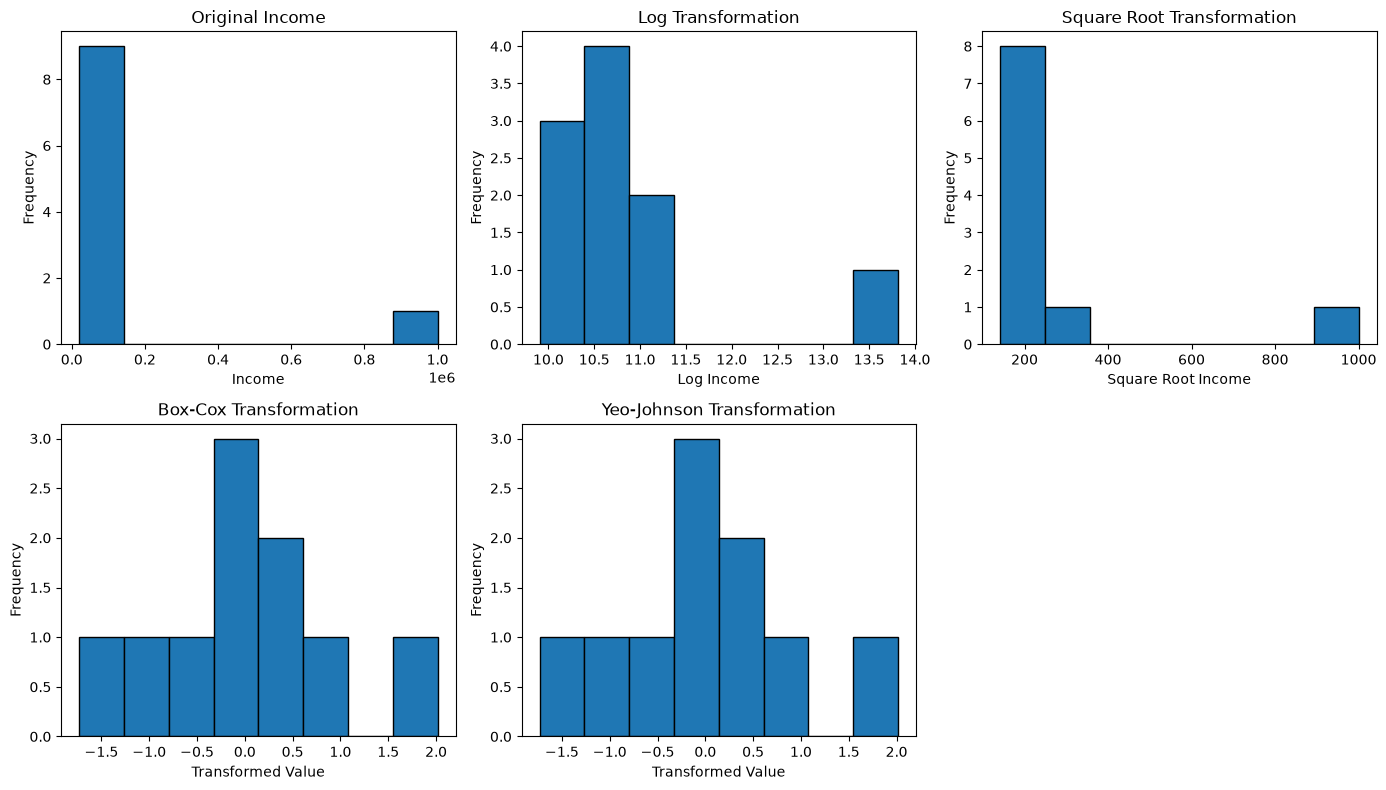


Yeo-Johnson with Zero and Negative Values:
   Feature  Transformed_Feature
0      -10            -1.606789
1       -5            -0.894341
2        0            -0.241164
3        2            -0.019003
4        5             0.290015
5       10             0.776220
6       20             1.695062

Important:
This notebook fits transformations to the full sample for demonstration.
In a real ML workflow, split the data first.
Fit learned transformation parameters on training data only.
Use the fitted transformer to transform the test data.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew
from sklearn.preprocessing import PowerTransformer

# --------------------------------------------------
# 1. Create a sample dataset
# --------------------------------------------------

df = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Income": [
        20000, 25000, 30000, 35000, 40000,
        45000, 50000, 60000, 80000, 1000000
    ]
})

print("Original Dataset:")
print(df)

# --------------------------------------------------
# 2. Inspect the original income distribution
# --------------------------------------------------

print("\nOriginal Income Statistics:")
print(df["Income"].describe())

original_skewness = skew(df["Income"])

print("\nOriginal Income Skewness:", round(original_skewness, 4))

# --------------------------------------------------
# 3. Apply Log Transformation
# --------------------------------------------------

df["Log_Income"] = np.log1p(df["Income"])

print("\nLog Transformation:")
print(df[["Income", "Log_Income"]])

print(
    "\nLog Transformation Skewness:",
    round(skew(df["Log_Income"]), 4)
)

# --------------------------------------------------
# 4. Apply Square Root Transformation
# --------------------------------------------------

df["Sqrt_Income"] = np.sqrt(df["Income"])

print("\nSquare Root Transformation:")
print(df[["Income", "Sqrt_Income"]])

print(
    "\nSquare Root Transformation Skewness:",
    round(skew(df["Sqrt_Income"]), 4)
)

# --------------------------------------------------
# 5. Apply Box-Cox Transformation
# Box-Cox requires strictly positive values.
# --------------------------------------------------

box_cox = PowerTransformer(method="box-cox")

df["BoxCox_Income"] = box_cox.fit_transform(
    df[["Income"]]
).ravel()

print("\nBox-Cox Transformation:")
print(df[["Income", "BoxCox_Income"]])

print(
    "\nBox-Cox Transformation Skewness:",
    round(skew(df["BoxCox_Income"]), 4)
)

# --------------------------------------------------
# 6. Apply Yeo-Johnson Transformation
# Yeo-Johnson supports positive, zero, and negative values.
# --------------------------------------------------

yeo_johnson = PowerTransformer(method="yeo-johnson")

df["YeoJohnson_Income"] = yeo_johnson.fit_transform(
    df[["Income"]]
).ravel()

print("\nYeo-Johnson Transformation:")
print(df[["Income", "YeoJohnson_Income"]])

print(
    "\nYeo-Johnson Transformation Skewness:",
    round(skew(df["YeoJohnson_Income"]), 4)
)

# --------------------------------------------------
# 7. Compare the Skewness of All Versions
# --------------------------------------------------

comparison = pd.DataFrame({
    "Technique": [
        "Original",
        "Log Transformation",
        "Square Root Transformation",
        "Box-Cox Transformation",
        "Yeo-Johnson Transformation"
    ],
    "Skewness": [
        skew(df["Income"]),
        skew(df["Log_Income"]),
        skew(df["Sqrt_Income"]),
        skew(df["BoxCox_Income"]),
        skew(df["YeoJohnson_Income"])
    ]
})

print("\nSkewness Comparison:")
print(comparison.round(4))

# --------------------------------------------------
# 8. Visualize the Original and Transformed Data
# --------------------------------------------------

plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.hist(df["Income"], bins=8, edgecolor="black")
plt.title("Original Income")
plt.xlabel("Income")
plt.ylabel("Frequency")

plt.subplot(2, 3, 2)
plt.hist(df["Log_Income"], bins=8, edgecolor="black")
plt.title("Log Transformation")
plt.xlabel("Log Income")
plt.ylabel("Frequency")

plt.subplot(2, 3, 3)
plt.hist(df["Sqrt_Income"], bins=8, edgecolor="black")
plt.title("Square Root Transformation")
plt.xlabel("Square Root Income")
plt.ylabel("Frequency")

plt.subplot(2, 3, 4)
plt.hist(df["BoxCox_Income"], bins=8, edgecolor="black")
plt.title("Box-Cox Transformation")
plt.xlabel("Transformed Value")
plt.ylabel("Frequency")

plt.subplot(2, 3, 5)
plt.hist(df["YeoJohnson_Income"], bins=8, edgecolor="black")
plt.title("Yeo-Johnson Transformation")
plt.xlabel("Transformed Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. Demonstrate Yeo-Johnson with Zero and Negative Values
# --------------------------------------------------

values_with_zero_and_negative = pd.DataFrame({
    "Feature": [-10, -5, 0, 2, 5, 10, 20]
})

yeo_johnson_mixed = PowerTransformer(method="yeo-johnson")

values_with_zero_and_negative["Transformed_Feature"] = (
    yeo_johnson_mixed.fit_transform(
        values_with_zero_and_negative[["Feature"]]
    ).ravel()
)

print("\nYeo-Johnson with Zero and Negative Values:")
print(values_with_zero_and_negative)

# --------------------------------------------------
# 10. Important ML Workflow Note
# --------------------------------------------------

print("\nImportant:")
print("This notebook fits transformations to the full sample for demonstration.")
print("In a real ML workflow, split the data first.")
print("Fit learned transformation parameters on training data only.")
print("Use the fitted transformer to transform the test data.")